# N05: Museum B, scored once

The test corpus: 600 paintings from 44 artists never seen in dev. Nothing is tuned here. Every rung runs with the
frozen config, their top 5 are pooled and graded by the same frozen judge, then scored.

Absolute scores are not comparable with dev (different paintings, 600 vs 480): compare the **gaps between rungs**.

In [1]:

import pandas as pd

from deep_learning_project_waerniers_lamy.nlp import utils as u

c:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
frozen = u.check_frozen()
paintings = u.load_corpus("test")
descriptions = u.load_descriptions()
queries = u.QUERIES["text"].tolist()
scores = {
    "R0 random": u.rung_random(paintings, queries),
    "R1 metadata": u.rung_metadata(paintings, queries),
    "R2 description": u.rung_description(paintings, queries, descriptions),
    "R3 description+metadata": u.rung_description_metadata(paintings, queries, descriptions),
    "R4 siglip image": u.rung_siglip(paintings, queries),
    "R5 hybrid": u.rung_hybrid(paintings, queries, descriptions),
}
print("artist named in test descriptions:", round(u.artist_leak_rate(paintings, descriptions), 3))
u.judge_with_llm("test", scores, paintings)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4649.60it/s]
[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|██████████| 408/408 [00:00<00:00, 522.95it/s]


artist named in test descriptions: 0.002
799 new (query, painting) pairs to grade with google/gemini-3.8-flash
100/799
200/799
300/799
400/799
500/799
600/799
700/799
799 judgments in C:\Users\Vincent\GitHub\Vincent-20-100\deep-learning-project-waerniers-lamy\results\nlp\qrels_test.json, 0 failed


{'q01': {'s54_r0455': 1,
  's49_r0463': 0,
  's54_r0337': 2,
  's54_r0547': 1,
  's49_r0495': 0,
  's54_r0481': 2,
  's58_r0222': 0,
  's54_r0039': 0,
  's54_r0378': 2,
  's54_r0443': 2,
  's51_r0217': 0,
  's54_r0400': 2,
  's51_r1004': 0,
  's54_r0175': 0,
  's54_r0700': 1,
  's54_r0385': 2,
  's54_r0458': 0,
  's54_r0032': 0,
  's51_r0610': 0},
 'q02': {'s51_r1105': 0,
  's54_r0389': 2,
  's54_r0026': 0,
  's54_r0061': 0,
  's54_r0485': 2,
  's54_r0349': 1,
  's42_r0449': 0,
  's49_r0773': 0,
  's54_r0805': 2,
  's49_r0854': 0,
  's51_r0968': 0,
  's54_r0230': 2,
  's54_r0481': 0,
  's54_r0263': 2,
  's54_r0248': 2,
  's54_r0111': 0,
  's54_r0599': 2,
  's54_r0152': 0,
  's54_r0821': 2},
 'q03': {'s42_r0808': 0,
  's42_r0283': 2,
  's42_r0210': 1,
  's54_r0378': 0,
  's42_r0294': 1,
  's42_r0802': 1,
  's51_r1084': 0,
  's58_r0412': 1,
  's58_r0669': 1,
  's51_r0669': 0,
  's58_r0274': 2,
  's58_r0243': 1,
  's42_r0282': 0,
  's58_r0061': 2,
  's58_r0385': 0,
  's49_r0966': 2,
  's5

### Judging

Same frozen judge and prompt as on dev: it sees only the query and the image.

## Results

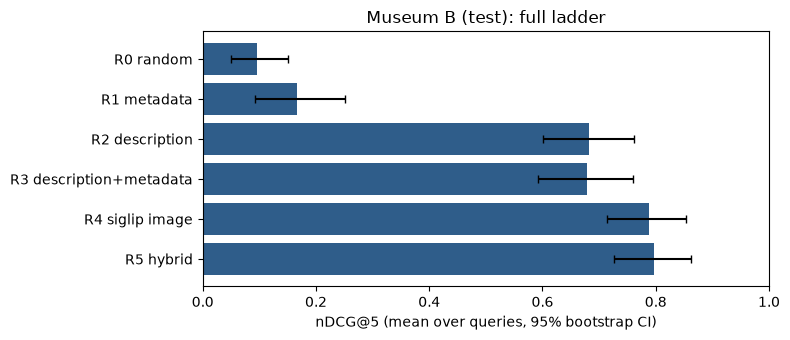

,rung,queries,nDCG@5,nDCG low,nDCG high,Success@5,Success low,Success high,judged@5
0,R0 random,40,0.096,0.050,0.151,0.225,0.100,0.350,1.0
1,R1 metadata,40,0.166,0.092,0.251,0.250,0.125,0.400,1.0
2,R2 description,40,0.683,0.601,0.762,0.825,0.700,0.925,1.0
3,R3 description+metadata,40,0.679,0.592,0.759,0.825,0.700,0.925,1.0
4,R4 siglip image,40,0.788,0.714,0.853,0.900,0.800,0.975,1.0
5,R5 hybrid,40,0.797,0.726,0.862,0.850,0.725,0.950,1.0


,system,reference,delta nDCG@5,p,p (Holm)
0,R2 description,R1 metadata,0.5174,0.0001,0.0003
1,R4 siglip image,R1 metadata,0.6215,0.0001,0.0003
2,R5 hybrid,R4 siglip image,0.0097,0.7810,0.7810


In [3]:
per_query = u.per_query_scores("test", scores, paintings)
table = u.summary_table(per_query)
u.plot_ladder(table, "Museum B (test): full ladder")
display(table)
u.compare(per_query, [("R2 description", "R1 metadata"), ("R4 siglip image", "R1 metadata"),
                      ("R5 hybrid", frozen["best_single"])])

## Gaps to the baseline, dev vs Museum B

In [4]:
dev_table = pd.read_csv(u.RESULTS_DIR / "dev_summary.csv").set_index("rung")["nDCG@5"]
test_table = table.set_index("rung")["nDCG@5"]
pd.DataFrame({"dev gap to R1": dev_table - dev_table["R1 metadata"],
              "test gap to R1": test_table - test_table["R1 metadata"]}).round(3)

,dev gap to R1,test gap to R1
rung,,
R0 random,-0.065,-0.070
R1 metadata,0.000,0.000
R2 description,0.550,0.517
R3 description+metadata,0.569,0.513
R4 siglip image,0.669,0.622
R5 hybrid,0.693,0.631


In [5]:
table.to_csv(u.RESULTS_DIR / "test_summary.csv", index=False)
per_query.to_csv(u.RESULTS_DIR / "test_per_query.csv", index=False)